In [48]:
import os
import uuid
import cv2
import torch
import numpy as np
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

from torchvision.ops import nms
from sklearn.decomposition import PCA
import hdbscan
import open_clip
from ultralytics import YOLO


In [49]:
# ------------------
# Config
# ------------------
YOLO_MODEL_A = "models/benthic_object_detector.pt"
YOLO_MODEL_B = "models/midwater_object_detector.pt"
VIDEO_PATH = "ray_video.mp4"
FRAME_STRIDE_SECONDS = 0.5
ROI_DIR = "rois"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLIP_CHECKPOINT = "open_clip_pytorch_model_bioclip2.bin"
CONF_THRESHOLD = 0.01   # as low as YOLO allows reliably
IOU_THRESHOLD = 0.9     # very permissive NMS inside YOLO
NMS_IOU_THRESH = 0.5
MIN_BOX_AREA = 32 * 32
OUTPUT_DIR = "embeddings"
os.makedirs(ROI_DIR, exist_ok=True)


In [50]:
# ------------------
# Load YOLO models
# ------------------
yolo_model_1 = YOLO(YOLO_MODEL_A)
yolo_model_2 = YOLO(YOLO_MODEL_B)



In [51]:
# ------------------
# Load CLIP
# ------------------
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms('hf-hub:imageomics/bioclip-2')
tokenizer = open_clip.get_tokenizer('hf-hub:imageomics/bioclip-2')
clip_model = clip_model.to(DEVICE).eval()


'(ProtocolError('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)), '(Request ID: e09368a0-34ff-483b-8065-ef3808b577a0)')' thrown while requesting HEAD https://huggingface.co/imageomics/bioclip-2/resolve/main/open_clip_config.json
Retrying in 1s [Retry 1/5].


In [52]:
# =========================
# VIDEO FRAME SAMPLER
# =========================
def sample_video_frames(video_path, every_seconds):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    stride = int(fps * every_seconds)

    frame_idx = 0
    sample_idx = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % stride == 0:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            yield sample_idx, Image.fromarray(rgb)
            sample_idx += 1

        frame_idx += 1

    cap.release()


In [53]:
# =========================
# EMBEDDING FUNCTION
# =========================
def embed_images(images):
    if not images:
        return np.empty((0, 512))

    with torch.no_grad():
        batch = torch.stack([clip_preprocess(img) for img in images]).to(DEVICE)
        feats = clip_model.encode_image(batch)
        feats = feats / feats.norm(dim=-1, keepdim=True)

    return feats.cpu().numpy()


In [54]:
# =========================
# MAIN PIPELINE
# =========================
all_roi_images = []
all_roi_paths = []

print("Processing video...")

for frame_id, image in tqdm(
    sample_video_frames(VIDEO_PATH, FRAME_STRIDE_SECONDS),
    desc="Frames"
):
    r1 = yolo_model_1(image, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD)[0]
    r2 = yolo_model_2(image, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD)[0]

    if len(r1.boxes) == 0 and len(r2.boxes) == 0:
        continue

    boxes = torch.cat([
        r1.boxes.xyxy.cpu() if len(r1.boxes) else torch.empty((0,4)),
        r2.boxes.xyxy.cpu() if len(r2.boxes) else torch.empty((0,4))
    ])

    scores = torch.cat([
        r1.boxes.conf.cpu() if len(r1.boxes) else torch.empty((0,)),
        r2.boxes.conf.cpu() if len(r2.boxes) else torch.empty((0,))
    ])

    keep = nms(boxes, scores, NMS_IOU_THRESH)
    boxes = boxes[keep]

    for box in boxes:
        x1, y1, x2, y2 = map(int, box.tolist())
        crop = image.crop((x1, y1, x2, y2))

        roi_id = f"{frame_id}_{uuid.uuid4()}"
        path = os.path.join(ROI_DIR, f"{roi_id}.jpg")
        crop.save(path, quality=95)

        all_roi_images.append(crop)
        all_roi_paths.append(path)

print(f"Total ROIs: {len(all_roi_images)}")


Processing video...


Frames: 0it [00:00, ?it/s]


0: 384x640 1 Eels, 1 Rays and Skates, 1088.1ms
Speed: 33.8ms preprocess, 1088.1ms inference, 37.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 2 Eel-likes, 1 Rays and Skates, 782.5ms
Speed: 2.3ms preprocess, 782.5ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


Frames: 1it [00:03,  3.44s/it]


0: 384x640 1 Eels, 1 Rays and Skates, 857.7ms
Speed: 4.4ms preprocess, 857.7ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 Rays and Skates, 776.3ms
Speed: 3.9ms preprocess, 776.3ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


Frames: 2it [00:05,  2.50s/it]

... (129 outputs left out)

Frames: 67it [02:15,  1.81s/it]


0: 384x640 1 Eels, 1 Rays and Skates, 658.7ms
Speed: 3.1ms preprocess, 658.7ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 3 Eel-likes, 1 Rays and Skates, 835.7ms
Speed: 3.5ms preprocess, 835.7ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)


Frames: 68it [02:17,  2.02s/it]

Total ROIs: 208


In [55]:
# =========================
# EMBED ALL ROIS
# =========================
embeddings = embed_images(all_roi_images)


In [62]:
# =========================
# CLUSTER
# =========================
n_samples, n_features = embeddings.shape
pca_dim = min(50, n_samples, n_features)
embeddings_reduced = PCA(n_components=pca_dim).fit_transform(embeddings)

# -------------------------
# Cluster with HDBSCAN
# -------------------------
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=5,
    metric='euclidean',
    cluster_selection_epsilon=0.02,
    max_cluster_size=50,
    cluster_selection_method='leaf'
)

cluster_labels = clusterer.fit_predict(embeddings)
num_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
print(f"Found {num_clusters} clusters (excluding noise)")

Found 6 clusters (excluding noise)


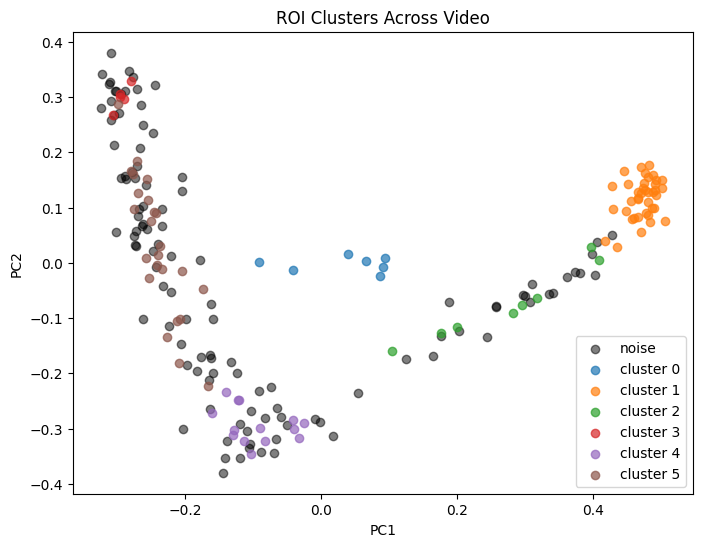

In [64]:
# =========================
# 2D VISUALIZATION
# =========================
embeddings_2d = PCA(n_components=2).fit_transform(embeddings)

plt.figure(figsize=(8,6))
for label in np.unique(cluster_labels):
    pts = embeddings_2d[cluster_labels == label]
    if label == -1:
        plt.scatter(pts[:,0], pts[:,1], c="black", label="noise", alpha=0.5)
    else:
        plt.scatter(pts[:,0], pts[:,1], label=f"cluster {label}", alpha=0.7)

plt.legend()
plt.title("ROI Clusters Across Video")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


Cluster 1 (39 ROIs)


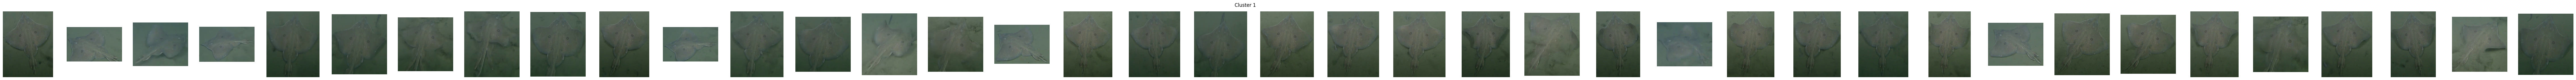


Cluster 4 (14 ROIs)


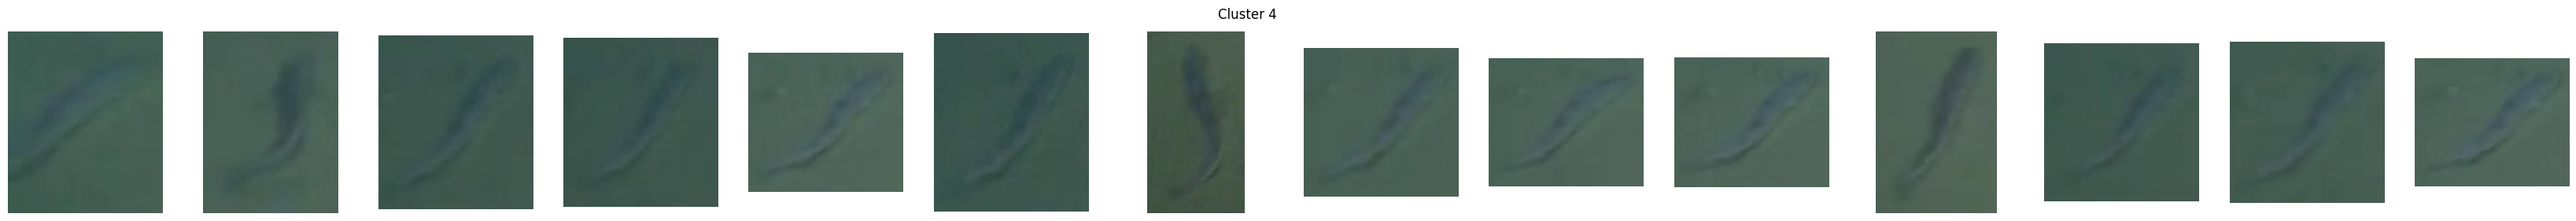


Cluster 5 (24 ROIs)


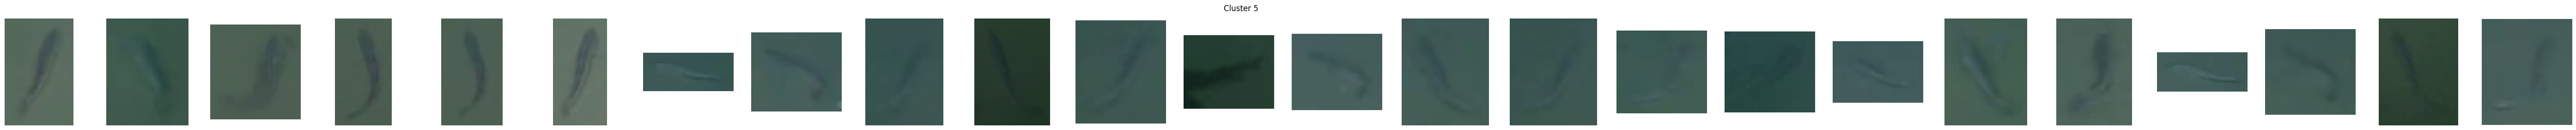


Cluster 3 (5 ROIs)


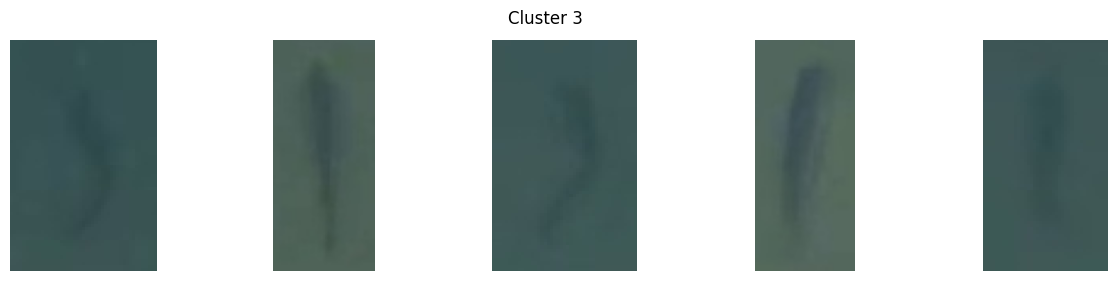


Cluster 0 (7 ROIs)


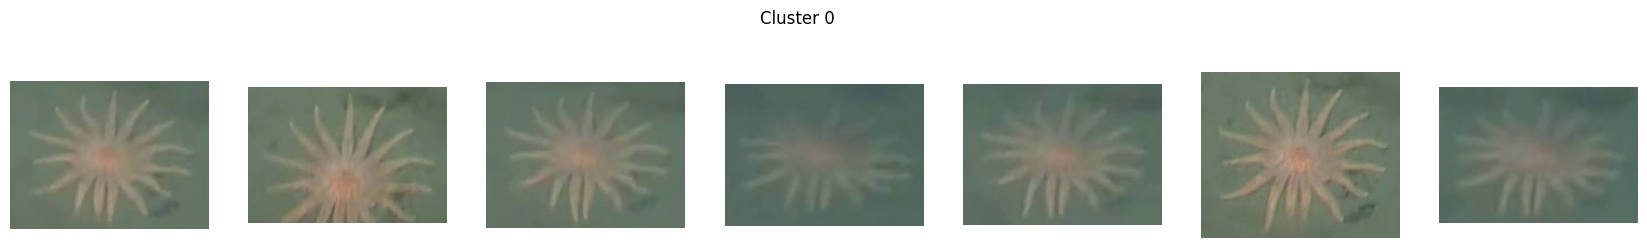


Cluster 2 (8 ROIs)


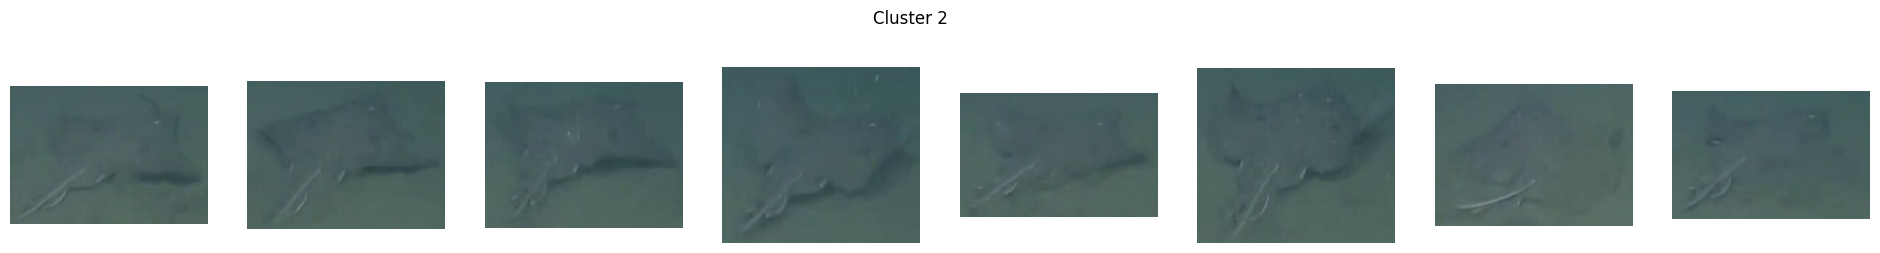


Noise (-1) ROIs: 111




In [65]:
# =========================
# DISPLAY SAMPLE IMAGES
# =========================
import random

clusters = {}
for path, label in zip(all_roi_paths, cluster_labels):
    clusters.setdefault(label, []).append(path)

# -------------------------
# Display clusters
# -------------------------
for label, paths in clusters.items():
    if label == -1:
        continue

    print(f"\nCluster {label} ({len(paths)} ROIs)")
    sample = random.sample(paths, min(100, len(paths)))

    fig, axes = plt.subplots(1, len(sample), figsize=(3 * len(sample), 3))
    if len(sample) == 1:
        axes = [axes]

    for ax, p in zip(axes, sample):
        ax.imshow(Image.open(p))
        ax.axis("off")

    plt.suptitle(f"Cluster {label}")
    plt.show()

# -------------------------
# Display noise samples
# -------------------------
if -1 in clusters:
    noise_paths = clusters[-1]
    print(f"\nNoise (-1) ROIs: {len(noise_paths)}")

    sample = random.sample(noise_paths, min(100, len(noise_paths)))

    fig, axes = plt.subplots(1, len(sample), figsize=(3 * len(sample), 3))
    if len(sample) == 1:
        axes = [axes]

    for ax, p in zip(axes, sample):
        ax.imshow(Image.open(p))
        ax.axis("off")

    plt.suptitle("Noise ROIs (unclustered)")
    plt.show()